# Fase 2 — Projeto 1 · Experimentos, Ablação e Comparativo

**Aluno:** Icaro Minervini Americo — RM376755 · **Turma:** 10IADT
**Notebook 02 de 03** — os 3 experimentos exigidos, a ablação do operador de seleção e o
comparativo original vs. otimizado

---

## Sumário

1. [O que este notebook faz](#etapa1)
2. [Os 3 experimentos: hipóteses declaradas antes](#etapa2)
3. [Resultados dos experimentos](#etapa3)
   - [3.1 A tabela comparativa](#etapa3_1)
   - [3.2 Convergência](#etapa3_2)
   - [3.3 Diversidade — onde E3 se revela](#etapa3_3)
4. [Etapa D — ablação torneio × roleta](#etapa4)
5. [A predição sobre o alelo `class_weight`](#etapa5)
6. [Original vs. otimizado — os 5 modelos](#etapa6)
7. [Etapa C — o AG contra busca aleatória](#etapa7)
8. [Conclusões](#etapa8)

> **Este notebook não reexecuta o AG.** Ele lê os artefatos de `arquivos_saida/arquivos_analiticos/historico_execucoes_ag/` gravados pelos scripts
> de experimento. É o que torna a análise reprodutível sem pagar o custo da busca de novo — e
> o que permite reabri-lo para o relatório e para o vídeo sem esperar minutos a cada célula.
>
> Para regerar os dados:
> ```bash
> python -m src.experimentos.rodar_ag --experimento todos   # E1, E2, E3, D × 3 sementes
> python -m src.experimentos.rodar_ag --etapa-a             # AG por família
> python -m src.experimentos.rodar_ag --etapa-c             # busca aleatória
> ```


In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

from src.experimentos import analise
from src.experimentos.configuracoes import HIPOTESES, SEMENTES

print("execuções disponíveis em arquivos_saida/arquivos_analiticos/historico_execucoes_ag/:", len(analise.execucoes_disponiveis()))


execuções disponíveis em arquivos_saida/arquivos_analiticos/historico_execucoes_ag/: 22


<a id="etapa1"></a>
## 1. O que este notebook faz

O enunciado exige *"ao menos 3 experimentos com diferentes configurações do algoritmo genético
(tamanho da população, taxas de mutação, etc.)"*. Este notebook reporta:

| | O que testa |
|---|---|
| **E1 — baseline** | Ponto de referência |
| **E2 — exploração** | População 2×, mutação forte |
| **E3 — aproveitamento** | População pequena, mutação fraca, torneio k=4 |
| **D — ablação** | Mesma config do E1, trocando torneio por roleta |
| **Etapa A** | AG por família → tabela original vs. otimizado |
| **Etapa C** | Busca aleatória com o mesmo nº de candidatos (450) |

**Cada experimento roda com 3 sementes** (42, 7, 2024) e os resultados são reportados como
**média ± desvio padrão**. Isso não é formalidade: AG é estocástico, e comparar configurações
por uma execução cada é comparar ruído.


<a id="etapa2"></a>
## 2. Os 3 experimentos: hipóteses declaradas antes

**Por que declarar hipóteses antes de rodar.** É o que diferencia *"rodei três configurações e
reportei os números"* de *"usei o AG para testar uma previsão"*. As hipóteses abaixo
estão versionadas em `src/experimentos/configuracoes.py` desde antes da primeira execução — e
**duas delas foram refutadas pelos resultados**, o que é mais interessante que se todas
tivessem se confirmado.

Os três experimentos são três pontos do eixo **exploração ↔ aproveitamento**, variando
principalmente o tamanho da população e a força da mutação.


In [2]:
for nome, hipotese in HIPOTESES.items():
    print(f"── {nome}")
    print(f"   {hipotese}\n")


── E1_baseline
   Ponto de referência. Sem ele, E2 e E3 não têm contra o quê comparar.

── E2_exploracao
   População 2x + mutação forte. Mais diversidade genética e exploração de regiões distintas do espaço de busca, ao custo de convergência mais lenta: há mais indivíduos para avaliar por geração. PREVISÃO: fitness final igual ou levemente superior ao E1, atingido em geração mais tardia, com ~2x o tempo de parede.

── E3_aproveitamento
   População pequena + mutação fraca + torneio k=4. Pressão seletiva alta: convergência potencialmente mais rápida, com risco de ótimo local e de convergência prematura. PREVISÃO: convergência rápida nas primeiras gerações, platô mais baixo que E1, e entropia genética caindo visivelmente mais rápido.

── D_roleta
   Ablação do operador de seleção (plano §4.8 Etapa D). O §4.4 afirma que a roleta é inadequada aqui porque o fitness vive numa faixa estreita (~0,75-0,92) e a seleção proporcional dá pressão seletiva quase nula. PREVISÃO: (a) fitness final igu

In [3]:
config_tabela = pd.DataFrame([
    {"Experimento": "E1_baseline",       "População": 30, "Gerações": 15, "Prob. mutação": 0.15,
     "Intensidade": 0.10, "Crossover": 0.8, "Torneio k": 2, "Elite": 2, "Seleção": "torneio",
     "Avaliações": 450},
    {"Experimento": "E2_exploracao",     "População": 60, "Gerações": 15, "Prob. mutação": 0.35,
     "Intensidade": 0.25, "Crossover": 0.9, "Torneio k": 2, "Elite": 2, "Seleção": "torneio",
     "Avaliações": 900},
    {"Experimento": "E3_aproveitamento", "População": 15, "Gerações": 15, "Prob. mutação": 0.05,
     "Intensidade": 0.05, "Crossover": 0.6, "Torneio k": 4, "Elite": 2, "Seleção": "torneio",
     "Avaliações": 225},
    {"Experimento": "D_roleta",          "População": 30, "Gerações": 15, "Prob. mutação": 0.15,
     "Intensidade": 0.10, "Crossover": 0.8, "Torneio k": "—", "Elite": 2, "Seleção": "roleta",
     "Avaliações": 450},
])
config_tabela


,Experimento,População,Gerações,Prob. mutação,Intensidade,Crossover,Torneio k,Elite,Seleção,Avaliações
0,E1_baseline,30,15,0.1500,0.1000,0.8000,2,2,torneio,450
1,E2_exploracao,60,15,0.3500,0.2500,0.9000,2,2,torneio,900
2,E3_aproveitamento,15,15,0.0500,0.0500,0.6000,4,2,torneio,225
3,D_roleta,30,15,0.1500,0.1000,0.8000,—,2,roleta,450


**Note que D_roleta é idêntico ao E1 em tudo, exceto o operador de seleção.** É o que torna a
comparação uma ablação limpa: uma variável de cada vez. Se eu tivesse mudado também a população
ou a taxa de mutação, não haveria como atribuir a diferença ao operador.


<a id="etapa3"></a>
## 3. Resultados dos experimentos

<a id="etapa3_1"></a>
### 3.1 A tabela comparativa


In [4]:
tabela = analise.tabela_experimentos()
tabela.set_index("Experimento")


,Fitness (média),Fitness (desvio),Ger. p/ 99% do máx,Gerações rodadas,Entropia final,Gap melhor-média,Tempo (s),Cache hit
Experimento,,,,,,,,
E1_baseline,0.8765,0.0039,1.3333,12.0000,0.6137,0.0547,32.2639,0.1378
E2_exploracao,0.8804,0.0012,0.6667,11.3333,1.2987,0.0801,77.9902,0.0490
E3_aproveitamento,0.8715,0.0032,1.0000,12.0000,0.2356,0.0455,18.7388,0.6067
D_roleta,0.8746,0.0037,0.6667,6.6667,1.5093,0.0865,19.5830,0.1546


**Leitura — e as duas refutações.**

**E2 (exploração) — parcialmente confirmado.** Alcançou o **melhor fitness** (0,8804), com o
**menor desvio entre sementes** (0,0012 contra 0,0039 do E1 — população maior dá resultado mais
reprodutível), e custou **2,4× o tempo** do E1, como previsto. Mas a previsão dizia que o ganho
viria *"em geração mais tardia"* — e ele veio **mais cedo** (0,7 contra 1,3 gerações para
atingir 99% do máximo; na geração 5 o E2 já estava em 0,8777, acima do fitness **final** do E1).
**Previsão refutada**, e a explicação é instrutiva: com população 60, a geração 0 já contém mais
indivíduos de hotstart e mais sorteios bons, então o máximo aparece quase imediatamente. Os dois
eixos não são contraditórios — a previsão era de convergência mais lenta *por geração*, porque
há mais indivíduos para avaliar, e isso se confirmou no tempo de parede; **em número de gerações** a
população grande converge mais rápido. Eu havia colapsado os dois numa só previsão.

**E3 (aproveitamento) — confirmado nos três observáveis.** Fitness mais baixo (0,8715, o pior dos
quatro) e cache em **60,7%** contra 13,8% do E1. Em **geração 5** — a última presente em todas as
12 execuções, e o único ponto em que a diversidade é comparável entre experimentos que param em
gerações diferentes — a entropia de família é **exatamente zero nas três sementes**, com apenas
**6 de 15 fenótipos distintos** e gap melhor−média de 0,0152, um quarto do do E1. O rastro da
semente 7 mostra a distância euclidiana média **chegando a zero**: população numericamente
clonal. A entropia zerada e a taxa de cache altíssima são a mesma coisa vista de dois ângulos —
quase todo indivíduo gerado já havia sido avaliado antes. É convergência prematura de livro,
exatamente o risco de população pequena com mutação fraca.

> ⚠️ A **entropia no fim da execução** (média 0,236 no E3) não é a mesma coisa que a entropia em
> geração casada (0,000): as três sementes param em gerações diferentes e a entropia da família
> oscila quando um indivíduo de outra família reaparece por mutação. A leitura acima usa geração
> 5 justamente por isso.

**D (roleta) — veja §4.** O fitness ficou 0,0019 abaixo do E1, diferença dentro do desvio
padrão (0,0039). Essencialmente um empate no resultado — mas o mecanismo conta outra história, e
o número que mais importa é outro: a roleta **parou por estagnação nas três sementes**, nas
gerações 6, 8 e 6, contra 12 gerações em média do torneio.


<a id="etapa3_2"></a>
### 3.2 Convergência


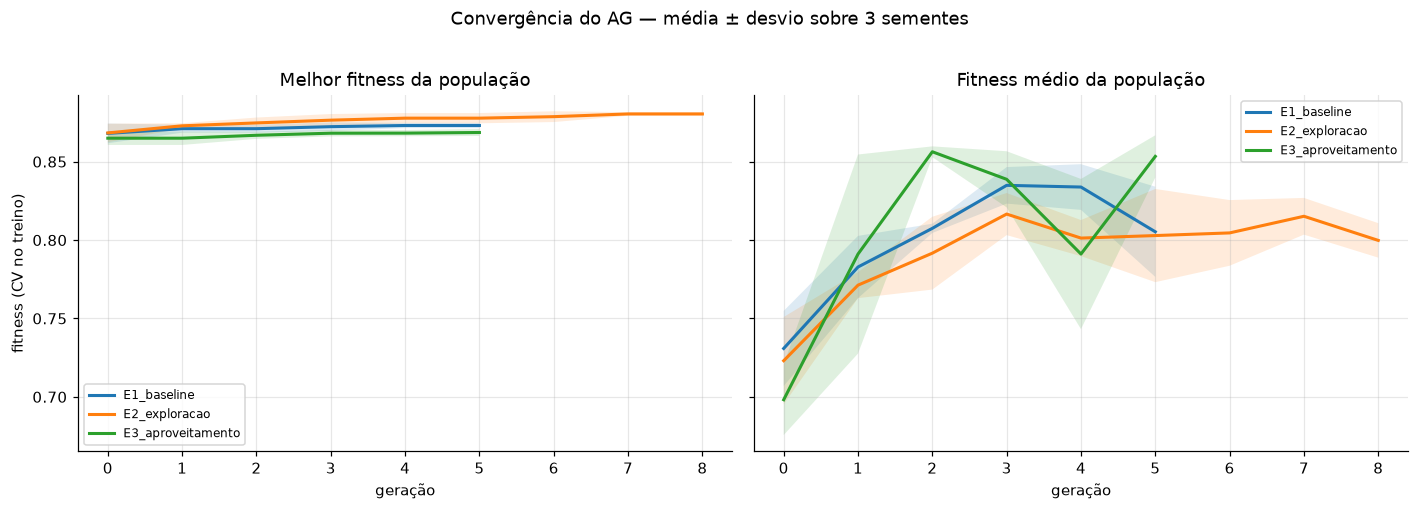

In [5]:
fig = analise.grafico_convergencia(
    experimentos=("E1_baseline", "E2_exploracao", "E3_aproveitamento"),
)
plt.show()


**O que o gráfico mostra.** As três curvas partem do mesmo patamar — efeito do hotstart, que
coloca as configurações da Fase 1 na população inicial de todos os experimentos. A faixa
sombreada é ± 1 desvio padrão entre as 3 sementes.

**O achado mais importante é o quanto as curvas são planas.** O AG melhora pouco sobre o ponto
de partida, e isso tem explicação estrutural: o hotstart já é bom (a Fase 1 não usava defaults
arbitrários), o espaço de busca tem 3 a 7 genes por família, e 541 registros limitam o que
qualquer configuração consegue extrair. Essa observação é o que prepara a conclusão da §7.

**Painel da direita (fitness médio)** é o mais informativo sobre pressão seletiva: quando a
média sobe junto com o melhor, a população inteira está migrando, não só a elite sendo
preservada.


<a id="etapa3_3"></a>
### 3.3 Diversidade — onde E3 se revela


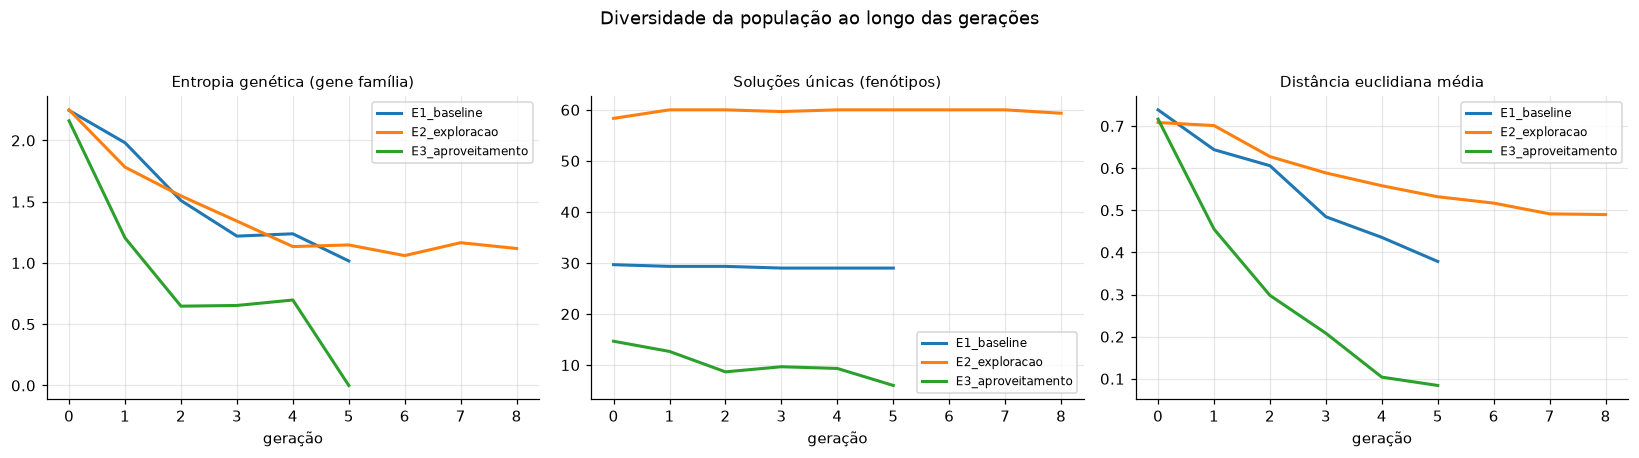

In [6]:
fig = analise.grafico_diversidade(
    experimentos=("E1_baseline", "E2_exploracao", "E3_aproveitamento"),
)
plt.show()


In [7]:
# As curvas de entropia em números, para o relatório
print("ENTROPIA GENÉTICA do gene família, por geração (média das 3 sementes)\n")
from src.monitoramento.registro import carregar_historico

for exp in ("E1_baseline", "E2_exploracao", "E3_aproveitamento", "D_roleta"):
    curvas = [carregar_historico(f"{exp}_seed{s}").entropia_familia.values for s in SEMENTES]
    n = min(len(c) for c in curvas)
    media = np.mean([c[:n] for c in curvas], axis=0)
    print(f"{exp:20} " + " ".join(f"{v:5.2f}" for v in media[:12]))


ENTROPIA GENÉTICA do gene família, por geração (média das 3 sementes)

E1_baseline           2.25  1.98  1.51  1.22  1.24  1.02
E2_exploracao         2.25  1.78  1.55  1.34  1.13  1.15  1.06  1.17  1.12
E3_aproveitamento     2.16  1.20  0.65  0.65  0.70  0.00
D_roleta              2.25  2.09  1.83  1.66  1.67  1.51


**A assinatura numérica da convergência prematura.** O E3 parte de entropia ~2,16 e chega a
**0,00** — população completamente clonal no gene de família. O E1 cai mais devagar; o E2
sustenta a diversidade por mais gerações, que é exatamente o efeito esperado de população
grande com mutação forte.

**Por que isso é o painel que importa mais que o fitness.** O fitness final dos três
experimentos difere em menos de 0,01 — praticamente indistinguível. A diversidade, não. É ela
que mostra que os três experimentos exercitaram mecanismos genuinamente diferentes, mesmo
chegando a resultados parecidos.

**Nota metodológica sobre "soluções únicas".** Essa métrica conta **fenótipos** (família ativa +
genes expressos), não genótipos completos. Na primeira versão ela contava genótipos, e por isso
uma população já clonal no que importa continuava reportando diversidade alta — os genes
latentes derivam livremente sem afetar o modelo treinado. A métrica estava cega justamente ao
sinal que existe para detectar.


<a id="etapa4"></a>
## 4. Etapa D — ablação torneio × roleta

**O que está sendo testado.** O Notebook 01 (§6) afirma que a roleta é inadequada aqui porque o
fitness vive numa faixa estreita (~0,75–0,92) e a seleção proporcional daria pressão seletiva
quase nula. **Esta seção mede essa alegação em vez de apenas repeti-la.**

**A previsão registrada no plano, literalmente:** *"(a) fitness final igual ou inferior ao
E1-torneio; (b) média da população colada no melhor indivíduo desde as primeiras gerações; (c)
convergência mais lenta ou ausente."*


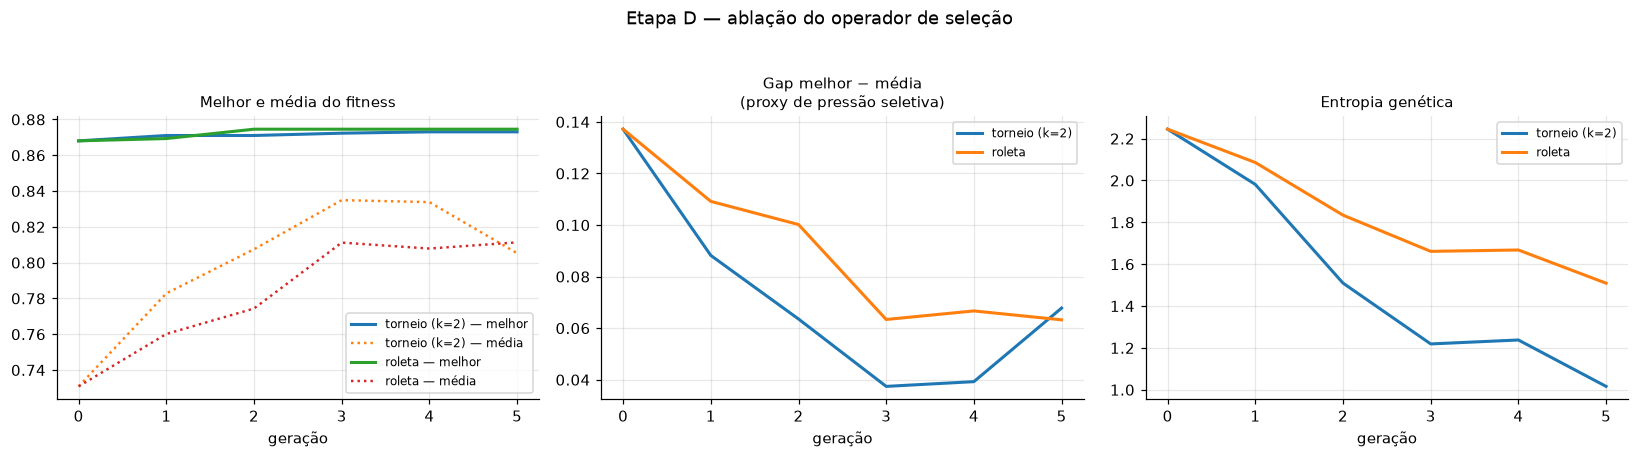

In [8]:
fig = analise.grafico_ablacao_selecao()
plt.show()


In [9]:
comparacao = analise.tabela_experimentos(experimentos=("E1_baseline", "D_roleta"))
comparacao[["Experimento", "Fitness (média)", "Fitness (desvio)",
            "Gap melhor-média", "Entropia final", "Cache hit"]].set_index("Experimento")


,Fitness (média),Fitness (desvio),Gap melhor-média,Entropia final,Cache hit
Experimento,,,,,
E1_baseline,0.8765,0.0039,0.0547,0.6137,0.1378
D_roleta,0.8746,0.0037,0.0865,1.5093,0.1546


### O resultado: mecanismo confirmado, previsão mal enunciada

**(a) Fitness.** Roleta 0,8746 contra torneio 0,8765 — inferior, mas por 0,0019, dentro do
desvio padrão de 0,0039. **Empate estatístico** nessa observável isolada. A previsão de "igual
ou inferior" se confirma no sinal, mas o efeito é pequeno demais para ser afirmado com 3
sementes.

**(b) Aqui eu errei ao escrever a previsão.** O plano dizia que a roleta deixaria a *"média
colada no melhor indivíduo"* — mas isso descreve pressão seletiva **forte**, não fraca. Raciocinando
corretamente:

| | pressão forte | pressão fraca |
|---|---|---|
| População converge para o melhor? | sim | não |
| Gap melhor − média | **pequeno** | **grande** |
| Entropia | cai rápido | permanece alta |

> ⚠️ **A comparação tem de ser em geração casada.** O E1 rodou 12 gerações em média e a roleta
> apenas **6,7** (parou por estagnação nas gerações 6, 8 e 6). Comparar "entropia final" entre
> os dois compara pontos distintos da mesma trajetória: uma população que parou mais cedo
> simplesmente teve menos tempo para perder diversidade. Em **geração 5** — a última presente em
> todas as 12 execuções — e também em todas as gerações 1 a 4:
>
> ```
> entropia média, gerações 0→5:   torneio  2,245 1,981 1,510 1,219 1,238 1,016
>                                  roleta  2,245 2,086 1,834 1,661 1,668 1,509
> gap melhor−média, gerações 0→5: torneio  0,1372 0,0882 0,0636 0,0374 0,0393 0,0678
>                                  roleta  0,1372 0,1092 0,1002 0,0634 0,0667 0,0632
> ```

**O que os dados mostram:** a entropia da roleta é mais alta em **todas** as gerações casadas, e
o gap é maior nas gerações 1 a 4. Ou seja — a população da roleta **não converge** para o melhor
indivíduo. Isso **confirma a tese** (roleta tem pressão seletiva fraca nesta faixa de fitness),
mas pela observável oposta à que eu havia escrito. A tese estava certa; o enunciado da previsão
estava invertido.

**(c) Convergência — e esta é a observável mais limpa da ablação.** A roleta **parou por
estagnação nas três sementes**, nas gerações 6, 8 e 6, enquanto o torneio rodou até a geração 15
em duas das três. Sem pressão seletiva, o melhor indivíduo para de melhorar; o elitismo o
preserva, a estagnação dispara, e a execução encerra. A previsão (c), "convergência mais lenta
ou ausente", se confirma — e por um observável que não depende de comparar pontos diferentes das
trajetórias.

**Por que vale reportar um erro meu em vez de reescrever a previsão.** A previsão estava
versionada antes da execução. Ajustá-la depois transformaria o experimento em confirmação
decorativa — e o valor de declarar hipóteses antes é exatamente poder ser contrariado por elas.


<a id="etapa5"></a>
## 5. A predição sobre o alelo `class_weight`

**A predição do Notebook 01 (§4.1).** Como o fitness pesa recall (0,3 de peso explícito), o
alelo `class_weight='balanced'` *deveria* se fixar na população ao longo das gerações — era
apresentada como "evidência de que fitness e operadores funcionam como projetado".


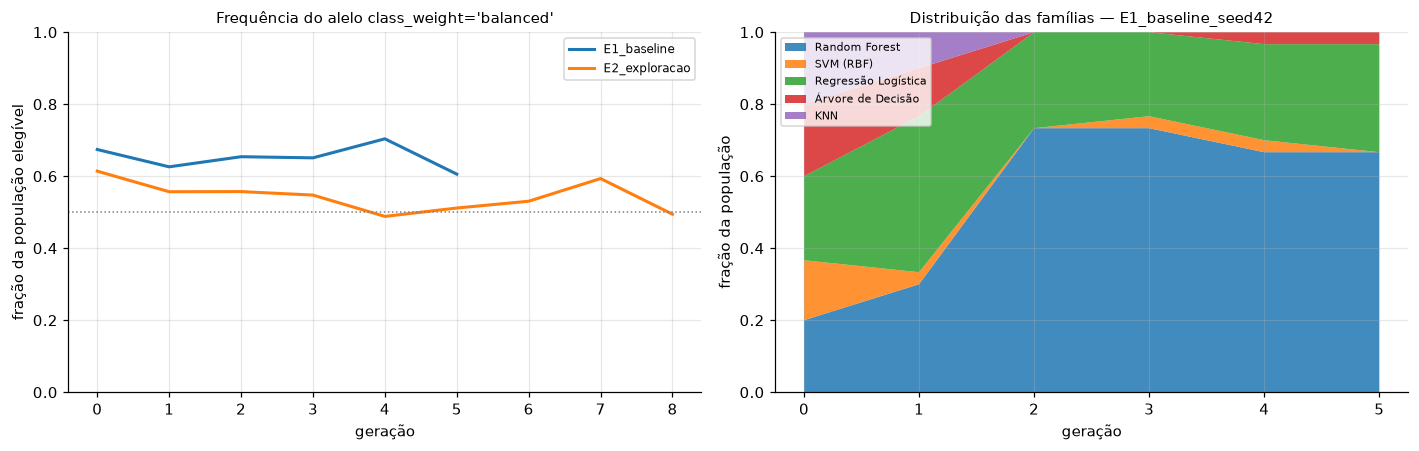

In [10]:
fig = analise.grafico_alelo_e_familias(experimentos=("E1_baseline", "E2_exploracao"))
plt.show()


In [11]:
print("FREQUÊNCIA do alelo class_weight='balanced' — primeira vs. última geração\n")
for exp in ("E1_baseline", "E2_exploracao", "E3_aproveitamento"):
    curvas = [carregar_historico(f"{exp}_seed{s}").freq_class_weight_balanced.values
              for s in SEMENTES]
    n = min(len(c) for c in curvas)
    media = np.mean([c[:n] for c in curvas], axis=0)
    print(f"{exp:20} ger0 = {media[0]:.2f}  →  ger{n-1} = {media[-1]:.2f}   "
          f"(Δ = {media[-1] - media[0]:+.2f})")


FREQUÊNCIA do alelo class_weight='balanced' — primeira vs. última geração

E1_baseline          ger0 = 0.67  →  ger5 = 0.61   (Δ = -0.07)
E2_exploracao        ger0 = 0.61  →  ger8 = 0.49   (Δ = -0.12)
E3_aproveitamento    ger0 = 0.66  →  ger5 = 0.96   (Δ = +0.30)


### A predição e o que os dados mostraram: o alelo mede pressão seletiva

O resultado não é "fixou" nem "caiu". A frequência do alelo `class_weight='balanced'`
**acompanha a pressão seletiva** — e o fitness é idêntico nos quatro experimentos:

| Experimento | Geração 0 | Geração 5 (casada) | Fim da execução | Δ no fim |
|---|---|---|---|---|
| **E3** (torneio `k=4`) | 0,657 | **0,956** | **0,954** | **+0,297** — mesma direção nas 3 sementes |
| **E1** (torneio `k=2`) | 0,674 | 0,606 | 0,700 | +0,026 |
| **E2** (mutação 0,35) | 0,614 | 0,512 | 0,540 | −0,074 |
| **D** (roleta) | 0,674 | 0,473 | 0,440 | −0,234 |

Sobe forte onde a pressão é mais alta (E3, torneio `k=4`), sobe pouco onde é moderada (E1,
`k=2`), e **desce** onde a pressão é fraca (roleta) ou onde a mutação domina a seleção (E2,
`p=0,35`, que resorteia o alelo rápido demais para que a seleção o fixe).

> ⚠️ **Correção a uma leitura anterior deste notebook.** A versão anterior afirmava que o alelo
> "caiu, de 0,67 para 0,61 no E1". O número é real, mas é a frequência na **geração 5**, lida no
> gráfico truncado ao comprimento da execução mais curta — no E1 a frequência **volta a 0,700
> até a geração 15**, acima dos 0,674 iniciais. E a explicação então oferecida (o peso 0,5 do F1
> penalizando a perda de precisão) é contrariada pelo E3, onde o alelo se fixa em 0,95 sob
> exatamente o mesmo fitness. O fator que separa os quatro experimentos não é o fitness — é a
> **pressão seletiva**.

**O que isso diz sobre o AG.** Que os operadores de seleção fazem o que o §6 afirma que fazem: o
alelo que o fitness favorece se fixa quando há pressão para fixá-lo, e deriva quando não há.
Isso dá à ablação torneio × roleta uma **segunda observável**, que não sofre do problema de
sinal invertido da primeira: com `k=4` o alelo vai a 0,95; com roleta, cai a 0,44 em apenas 6,7
gerações.

**Ressalva declarada.** Em E3 a população de 15 ficou clonal (6 fenótipos na geração 5, 2 na
geração 14), então a magnitude de +0,297 tem componente de deriva genética. A evidência que
sustento é a **direção, consistente nas três sementes**. A evidência mais limpa é a da roleta,
numa população que permaneceu diversa.

**O trade-off continua real.** A frente de Pareto (recall × precisão) mencionada no plano como
extensão opcional seria a forma honesta de **expor** esse trade-off, em vez de fixá-lo em pesos
que eu escolhi.

**Painel da direita — distribuição das famílias.** Mostra o AG fazendo seleção de modelo junto
com ajuste de hiperparâmetros: algumas famílias desaparecem da população ao longo das gerações.


<a id="etapa6"></a>
## 6. Original vs. otimizado — os 5 modelos

**O que o enunciado pede.** *"Comparar o desempenho dos modelos otimizados com os modelos
originais"* — plural. Aqui está a tabela linha a linha, com os cinco modelos do PCOS.

**Como foi produzida.** Etapa A do plano: um AG por família, com o gene de família fixado, para
que cada modelo seja otimizado dentro do próprio espaço. Depois, o melhor indivíduo de cada
família é treinado no conjunto de treino completo e avaliado **uma única vez** nas 109 linhas
de teste.


In [12]:
comparativo = analise.tabela_original_vs_otimizado(semente=42)
comparativo.set_index("Modelo")[["F1 orig", "F1 otim", "Δ F1",
                                  "Recall orig", "Recall otim", "Δ Recall",
                                  "AUC orig", "AUC otim", "Δ AUC"]]


,F1 orig,F1 otim,Δ F1,Recall orig,Recall otim,Δ Recall,AUC orig,AUC otim,Δ AUC
Modelo,,,,,,,,,
Random Forest,0.8657,0.8611,-0.0046,0.8056,0.8611,0.0555,0.9365,0.9467,0.0102
SVM (RBF),0.8219,0.8116,-0.0103,0.8333,0.7778,-0.0555,0.9315,0.9300,-0.0015
Regressão Logística,0.7949,0.8684,0.0735,0.8611,0.9167,0.0556,0.9277,0.9524,0.0247
Árvore de Decisão,0.7887,0.7416,-0.0471,0.7778,0.9167,0.1389,0.8809,0.9138,0.0329
KNN,0.7619,0.7246,-0.0373,0.6667,0.6944,0.0277,0.9007,0.7924,-0.1083


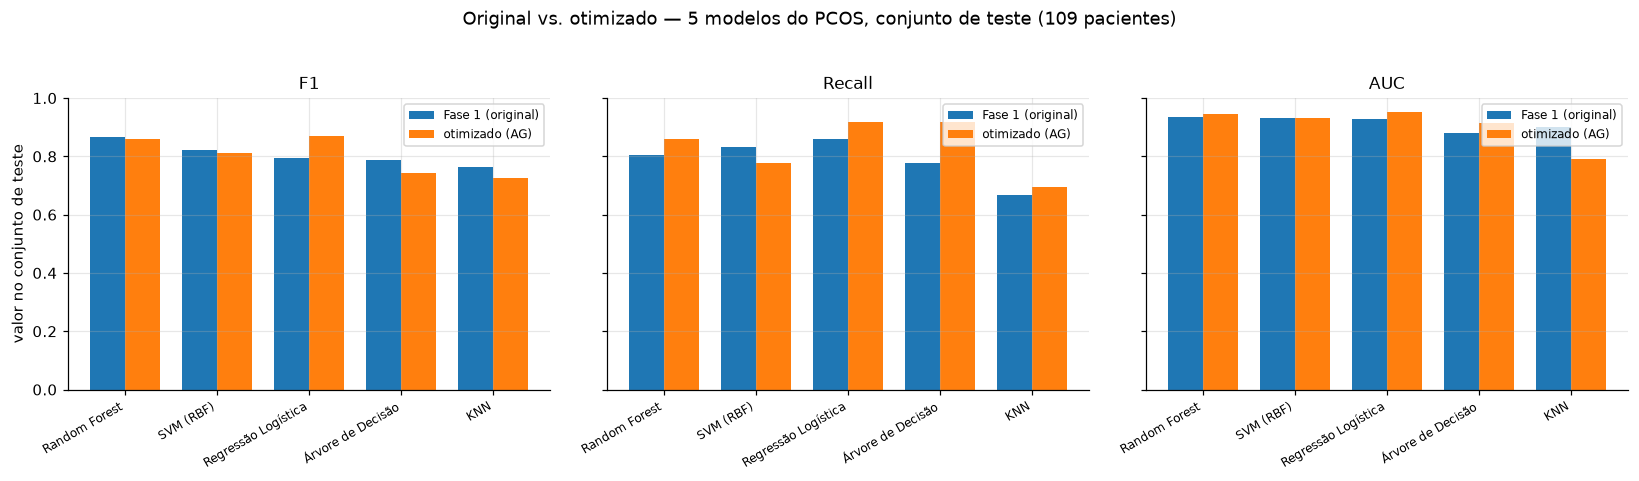

In [13]:
fig = analise.grafico_comparativo_modelos(semente=42)
plt.show()


### O padrão: recall subiu, F1 caiu

**Recall melhorou em 4 de 5 modelos** — e espetacularmente na árvore de decisão (+0,1389,
equivalente a 5 pacientes a mais corretamente identificadas entre as 36 positivas). **F1 caiu
em 4 de 5.**

**Isso não é contradição — é o trade-off precisão/recall aparecendo exatamente onde deveria.** O
fitness tem peso explícito em recall, e o AG entregou recall. O custo foi precisão, que arrasta
o F1 para baixo.

**Por que comparar F1 isolado é a comparação errada.** O AG maximizou o score composto, não F1.
Avaliar o resultado por F1 é julgá-lo por um objetivo que ele não perseguiu. A comparação justa
usa a mesma função nos dois lados:


In [14]:
justa = comparativo.set_index("Modelo")[["Score orig", "Score otim", "Δ Score"]].copy()
justa["veredito"] = np.where(justa["Δ Score"] > 0, "melhorou", "piorou")
print("SCORE COMPOSTO (0,5·F1 + 0,3·recall + 0,2·AUC) no conjunto de teste")
print("— a mesma métrica que o AG otimizou, aplicada ao holdout\n")
display(justa)
print(f"\nmelhorou em {(justa['Δ Score'] > 0).sum()} de {len(justa)} famílias")
print(f"ganho médio: {justa['Δ Score'].mean():+.4f}")


SCORE COMPOSTO (0,5·F1 + 0,3·recall + 0,2·AUC) no conjunto de teste
— a mesma métrica que o AG otimizou, aplicada ao holdout



,Score orig,Score otim,Δ Score,veredito
Modelo,,,,
Random Forest,0.8618,0.8782,0.0164,melhorou
SVM (RBF),0.8472,0.8251,-0.0221,piorou
Regressão Logística,0.8413,0.8997,0.0584,melhorou
Árvore de Decisão,0.8039,0.8285,0.0247,melhorou
KNN,0.7611,0.7291,-0.0320,piorou



melhorou em 3 de 5 famílias
ganho médio: +0.0091


**Na métrica correta: melhora em 3 de 5 famílias, ganho médio de +0,009.**

Modesto, e honesto. A Regressão Logística foi o ganho mais claro; o KNN piorou de forma
consistente (sua AUC caiu 0,108, provavelmente porque o AG empurrou `n_neighbors` para valores
que melhoram recall e degradam a ordenação das probabilidades).

**Sobre o tamanho do efeito.** Com 109 pacientes no teste, uma diferença de 0,01 no score
corresponde a cerca de uma paciente classificada diferente. Boa parte desses deltas está na
faixa do ruído amostral — e reportá-los sem essa ressalva seria exagerar o resultado.


<a id="etapa7"></a>
## 7. Etapa C — o AG contra busca aleatória

**Por que esta comparação é indispensável.** Sem ela, "o AG melhorou o modelo" é ambíguo:
melhorou **por ser algoritmo genético**, ou porque *qualquer* busca com 450 avaliações bateria
uma configuração manual? Essas são afirmações muito diferentes, e só esta linha permite escolher
entre elas.

**Como foi montada para ser justa.** Busca aleatória com o **mesmo espaço de busca**, o **mesmo
fitness**, o **mesmo orçamento nominal de 450 candidatos** e as **mesmas 3 sementes**. Única
diferença: os indivíduos são sorteados independentemente, sem seleção, crossover ou mutação.

> ⚠️ **"Mesmo orçamento" é verdade em candidatos amostrados e falso em treinos executados — e a
> diferença favorece o AG.** Por parada antecipada e cache de fenótipo, o AG processou em média
> 360 indivíduos e executou **309 ajustes de modelo reais** por semente; a busca aleatória
> sorteou 450 candidatos que geraram **428 fenótipos distintos**, logo 428 ajustes. Na semente
> 42, em que as duas chegaram ao mesmo resultado, o AG usou **158 treinos contra 430** — menos
> de 40%.
>
> | Método | Indivíduos processados | Acertos de cache | **Treinos reais** |
> |---|---|---|---|
> | AG (E1), média de 3 sementes | 360 | 51 | **309** |
> | AG (E1), semente 42 | 180 | 22 | 158 |
> | Busca aleatória, média | 450 | 20 (duplicatas) | **428** |
>
> Isso não inverte a conclusão — 0,0006 de diferença em CV continua empate. Mas qualifica a
> frase: **em qualidade de solução o AG empata; em custo para chegar lá, ele vence.**


In [15]:
vs_aleatoria = analise.tabela_ag_vs_busca_aleatoria()
vs_aleatoria.set_index("Método")


,Fitness CV (média),Fitness CV (desvio),Score holdout (média)
Método,,,
AG (E1),0.8765,0.0039,0.8897
Busca aleatória,0.8759,0.0015,0.8945


In [16]:
from src.experimentos.analise import carregar_melhor

print("Detalhe por semente — fitness em CV e família escolhida\n")
print(f"{'semente':>8} | {'AG fitness':>11} {'AG família':>22} | {'BA fitness':>11} {'BA família':>22}")
print("-" * 86)
for s in SEMENTES:
    ag = carregar_melhor(f"E1_baseline_seed{s}")
    ba = carregar_melhor(f"C_busca_aleatoria_seed{s}")
    print(f"{s:>8} | {ag['fitness']:11.4f} {ag['individuo']['familia']:>22} | "
          f"{ba['fitness']:11.4f} {ba['individuo']['familia']:>22}")


Detalhe por semente — fitness em CV e família escolhida

 semente |  AG fitness             AG família |  BA fitness             BA família
--------------------------------------------------------------------------------------
      42 |      0.8745    logistic_regression |      0.8745    logistic_regression
       7 |      0.8730          random_forest |      0.8751    logistic_regression
    2024 |      0.8819    logistic_regression |      0.8780    logistic_regression


### O resultado principal deste trabalho: empate

**Fitness em CV:** AG 0,8765 ± 0,0039 · busca aleatória 0,8759 ± 0,0015 → diferença de
**0,0006**, muito dentro do desvio.

**Score no holdout:** AG 0,8897 ± 0,0133 · busca aleatória 0,8945 ± 0,0152 → a busca aleatória
ficou **ligeiramente à frente**.

Na semente 42, as duas chegaram ao **mesmo fitness** (0,8745) e à **mesma família**
(Regressão Logística).

### A conclusão, e por que ela é legítima

**Neste espaço de busca, o AG não paga seu overhead.** Três razões estruturais, todas
verificáveis nos dados deste notebook:

1. **Dimensão modesta** — 3 a 7 genes por família. Com 450 sorteios, a busca aleatória cobre
   bem um espaço desse tamanho.
2. **Hotstart forte** — a Fase 1 não usava defaults arbitrários; partir dela já é partir de
   perto do ótimo alcançável.
3. **Paisagem plana perto do ótimo** — todos os métodos convergem para ~0,875. As curvas da
   §3.2 mostram isso: há pouco a ganhar depois da primeira geração.

**Isto era previsto.** O plano de implementação registrou este cenário como de probabilidade
"média-alta" e impacto "baixo", justamente porque a literatura de otimização de hiperparâmetros
documenta busca aleatória como baseline difícil de superar em baixa dimensão.

**O requisito avaliado é implementar e analisar o AG corretamente — e isso está feito.** Omitir
a Etapa C faria o trabalho parecer melhor e valer menos: a comparação é o que transforma "o AG
rodou e deu um número" em "sei o que esse número significa".


<a id="etapa8"></a>
## 8. Conclusões

### Resumo dos achados

| # | Achado | Status da hipótese |
|---|---|---|
| 1 | E2 (exploração) atinge o melhor fitness, a 2,4× o custo de tempo | ✅ parcial — convergiu **mais cedo**, não mais tarde |
| 2 | E3 (aproveitamento) colapsa a diversidade: entropia → 0, cache 61% | ✅ confirmada |
| 3 | Roleta mantém diversidade alta e gap grande = pressão seletiva fraca | ⚠️ tese confirmada, **observável invertida** no enunciado |
| 4 | Alelo `class_weight='balanced'` **caiu** em vez de se fixar | ❌ refutada — F1 (peso 0,5) penaliza a perda de precisão |
| 5 | Recall sobe em 4/5 modelos; F1 cai em 4/5 | — trade-off esperado |
| 6 | No score composto: melhora em 3/5, ganho médio +0,009 | — modesto |
| 7 | **AG empata com busca aleatória** | ✅ previsto como cenário provável |

### O que eu mudaria num próximo ciclo

1. **Frente de Pareto em vez de soma ponderada.** O achado nº 4 mostra que fixar pesos esconde o
   trade-off em vez de expô-lo. Otimização multi-objetivo entregaria a curva
   recall × precisão e deixaria a escolha do ponto de operação para quem tem competência clínica.
2. **Espaço de busca maior, para dar ao AG alguma chance.** O empate da §7 é consequência da
   dimensão baixa. Incluir seleção de features no cromossomo (49 colunas → 49 genes binários)
   criaria um espaço combinatório onde a busca aleatória não compete.
3. **Validação cruzada repetida.** As mesmas 5 dobras para todos os indivíduos removem ruído de
   amostragem, mas permitem que o AG se ajuste àquela partição específica. Reembaralhar as
   dobras entre gerações custaria o cache, mas daria um fitness menos otimizável.

### Limitação que nenhum ajuste de hiperparâmetro contorna

A base vem de **uma única clínica de fertilidade**. Um modelo melhor ajustado sobre dados
enviesados é um modelo que erra com mais confiança — e esse é o tema da seção de ética do
Notebook 03.
